In [4]:
import pandas as pd 
import numpy as np 
import matplotlib as plt


In [5]:
cv=pd.read_csv("Customer_dataset.csv")

In [6]:
cv.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [7]:
cv.dtypes

customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges            str
Churn                   str
dtype: object

In [8]:
cv.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [9]:
cv["Churn"]=cv["Churn"].map({"Yes":1,"No":0})
print(cv["Churn"])

0       0
1       0
2       1
3       0
4       1
       ..
7038    0
7039    0
7040    0
7041    1
7042    0
Name: Churn, Length: 7043, dtype: int64


In [10]:
cv.drop("customerID",axis=1)

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,0
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,0
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,0
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,Male,0,Yes,Yes,24,Yes,Yes,DSL,Yes,No,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.5,0
7039,Female,0,Yes,Yes,72,Yes,Yes,Fiber optic,No,Yes,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.9,0
7040,Female,0,Yes,Yes,11,No,No phone service,DSL,Yes,No,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,0
7041,Male,1,Yes,No,4,Yes,Yes,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.6,1


In [ ]:
cv["TotalCharges"]=pd.to_numeric(cv["TotalCharges"],errors="coerce")
print(cv["TotalCharges"].isnull().sum())

11


In [12]:
cv=cv.dropna(subset=["TotalCharges"])

In [13]:
print(cv["TotalCharges"].isnull().sum())

0


In [14]:
X = cv.drop(columns=["Churn", "customerID"], errors="ignore")
X = pd.get_dummies(X, drop_first=True, dtype=int)
Y = cv['Churn']

In [15]:
from sklearn.model_selection import train_test_split


In [16]:
X_train,X_test,Y_train,Ytest=train_test_split(X,Y,test_size=0.2,random_state=40,stratify=Y)

In [17]:
from sklearn import tree
model=tree.DecisionTreeClassifier(max_depth=5,
    min_samples_split=20,
    min_samples_leaf=10,
    random_state=40,class_weight="balanced")
model.fit(X_train,Y_train)

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",5
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",20
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",10
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary ` for details.",40
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current 

In [18]:
print(f"training accuracy is {model.score(X_train,Y_train)} percent")
print(f"training accuracy is {model.score(X_test,Ytest)} percent")


training accuracy is 0.7532444444444445 percent
training accuracy is 0.749822316986496 percent


In [19]:
from sklearn.metrics import (accuracy_score, precision_score,f1_score,recall_score,classification_report)

In [20]:
y_pred=model.predict(X_test)
print("accuracy score", accuracy_score(Ytest,y_pred))
print("Precision score", precision_score(Ytest,y_pred,zero_division=0))
print("recall score", recall_score(Ytest,y_pred,zero_division=0))
print("f1 score", f1_score(Ytest,y_pred,zero_division=0))
print("\nDETAILED REPORT:")
print("classification score", classification_report(Ytest,y_pred,zero_division=0))


accuracy score 0.749822316986496
Precision score 0.5195035460992907
recall score 0.7834224598930482
f1 score 0.6247334754797441

DETAILED REPORT:
classification score               precision    recall  f1-score   support

           0       0.90      0.74      0.81      1033
           1       0.52      0.78      0.62       374

    accuracy                           0.75      1407
   macro avg       0.71      0.76      0.72      1407
weighted avg       0.80      0.75      0.76      1407



In [21]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, recall_score, precision_score, f1_score

for depth in [3, 5, 7, 10, None]:
    model = DecisionTreeClassifier(
        max_depth=depth,
        min_samples_split=20,
        min_samples_leaf=10,
        random_state=40,
        class_weight="balanced"
    )

    model.fit(X_train, Y_train)
    y_pred = model.predict(X_test)

    print(f"\nMax depth: {depth}")
    print("Accuracy:", round(accuracy_score(Ytest, y_pred), 3))
    print("Precision:", round(precision_score(Ytest, y_pred, zero_division=0), 3))
    print("Recall:", round(recall_score(Ytest, y_pred, zero_division=0), 3))
    print("F1-score:", round(f1_score(Ytest, y_pred, zero_division=0), 3))


Max depth: 3
Accuracy: 0.682
Precision: 0.45
Recall: 0.896
F1-score: 0.599

Max depth: 5
Accuracy: 0.75
Precision: 0.52
Recall: 0.783
F1-score: 0.625

Max depth: 7
Accuracy: 0.724
Precision: 0.488
Recall: 0.821
F1-score: 0.612

Max depth: 10
Accuracy: 0.709
Precision: 0.471
Recall: 0.765
F1-score: 0.583

Max depth: None
Accuracy: 0.709
Precision: 0.469
Recall: 0.717
F1-score: 0.567


In [22]:
from sklearn.model_selection import cross_val_score
from sklearn.tree import DecisionTreeClassifier

model = DecisionTreeClassifier(
    max_depth=7,
    min_samples_split=20,
    min_samples_leaf=10,
    class_weight="balanced",
    random_state=40
)

scores = cross_val_score(
    model, X, Y,
    cv=5,
    scoring="f1"
)

print("F1 scores:", scores)
print("Mean F1 score:", scores.mean())

F1 scores: [0.61056751 0.63188976 0.6006192  0.57282502 0.6029106 ]
Mean F1 score: 0.6037624201703202


In [23]:
from sklearn.model_selection import GridSearchCV
param={"max_depth":[3,5,7,10],
       "min_samples_leaf":[5,10,20]}
grid=GridSearchCV(DecisionTreeClassifier(random_state=40,class_weight="balanced"),param,cv=5,scoring="f1")
grid.fit(X_train,Y_train)
print(grid.best_score_)
print(grid.best_params_)
best=grid.best_estimator_
print(best.score(X_test,Ytest))

0.6129682572469999
{'max_depth': 5, 'min_samples_leaf': 20}
0.7540867093105899


In [24]:
from sklearn.ensemble import RandomForestClassifier

In [25]:
rand=RandomForestClassifier(
    n_estimators=200,
    max_depth=7,
    min_samples_split=20,
    min_samples_leaf=10,
    random_state=40,
    class_weight="balanced",
    n_jobs=-1
)


In [26]:
rand.fit(X_train,Y_train)
print("training accuracy:",rand.score(X_train,Y_train))
print("training accuracy:",rand.score(X_test,Ytest))


training accuracy: 0.7751111111111111
training accuracy: 0.7626154939587776


In [27]:
from sklearn.metrics import (confusion_matrix,roc_auc_score)

In [28]:
predic=rand.predict(X_test)
print("f1_score:",f1_score(Ytest,predic))
print("recall:",recall_score(Ytest,predic))
print("precision:",precision_score(Ytest,predic))
print("\nConfusion matrix")
print(confusion_matrix(Ytest,predic))
print("\nclasification")
print(classification_report(Ytest,predic))
prob=rand.predict_proba(X_test)[:,1]
print("roc_auc_score",roc_auc_score(Ytest,prob))

f1_score: 0.6461864406779662
recall: 0.8155080213903744
precision: 0.5350877192982456

Confusion matrix
[[768 265]
 [ 69 305]]

clasification
              precision    recall  f1-score   support

           0       0.92      0.74      0.82      1033
           1       0.54      0.82      0.65       374

    accuracy                           0.76      1407
   macro avg       0.73      0.78      0.73      1407
weighted avg       0.82      0.76      0.77      1407

roc_auc_score 0.8634836492020024


In [29]:
from sklearn.model_selection import cross_val_predict
import numpy as np

train_probs = cross_val_predict(rand, X_train, Y_train, cv=5,
                                method="predict_proba")[:, 1]

thresholds = np.arange(0.3, 0.8, 0.02)
f1s = [f1_score(Y_train, train_probs >= t) for t in thresholds]
best_t = thresholds[np.argmax(f1s)]
print("Best threshold:", round(best_t, 2), "CV F1:", round(max(f1s), 3))

# check on the test set once
test_pred = (prob >= best_t).astype(int)
print("Test F1       :", f1_score(Ytest, test_pred))
print("Test recall   :", recall_score(Ytest, test_pred))
print("Test precision:", precision_score(Ytest, test_pred))

Best threshold: 0.56 CV F1: 0.634
Test F1       : 0.6525323910482921
Test recall   : 0.7406417112299465
Test precision: 0.5831578947368421


In [30]:
feature=pd.DataFrame({
    "Feature":X_train.columns,
    
    "Importance":rand.feature_importances_
}).sort_values(by="Importance",ascending=False)
print(feature.head(10).to_string(index=False))

                        Feature  Importance
                         tenure    0.190232
              Contract_Two year    0.134325
                   TotalCharges    0.124062
    InternetService_Fiber optic    0.101782
                 MonthlyCharges    0.068869
 PaymentMethod_Electronic check    0.056924
              Contract_One year    0.037844
             OnlineSecurity_Yes    0.035200
                TechSupport_Yes    0.029593
TechSupport_No internet service    0.022807


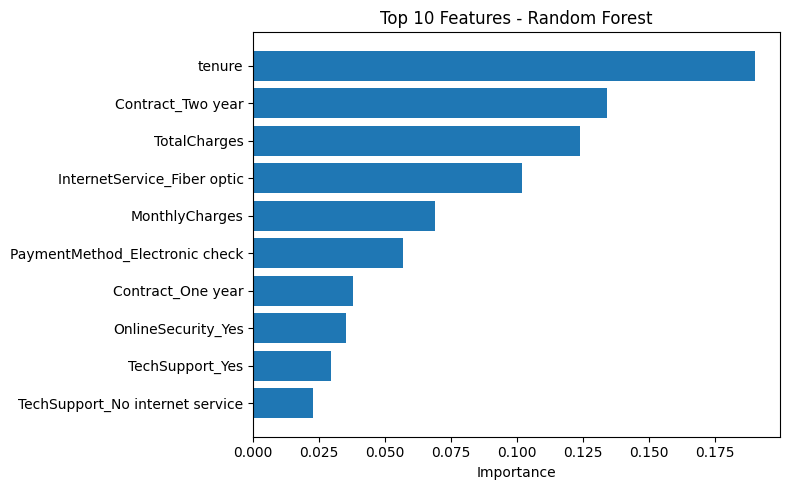

In [31]:
import matplotlib.pyplot as plt

top10 = feature.head(10).sort_values(by="Importance")   # smallest first so the biggest ends up on top
plt.figure(figsize=(8, 5))
plt.barh(top10["Feature"], top10["Importance"])
plt.xlabel("Importance")
plt.title("Top 10 Features - Random Forest")
plt.tight_layout()
plt.show()

In [40]:
from xgboost import XGBClassifier
X_tr,X_val,Y_tr,Y_val=train_test_split(X_train,Y_train,random_state=40,test_size=0.2,stratify=Y_train)

In [41]:
spw=(Y_train==0).sum()/(Y_train==1).sum()

In [49]:
xgb=XGBClassifier(
    n_estimators=1000,
    learning_rate=0.05,
    max_depth=3,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=spw,
    eval_metric="auc",
    early_stopping_rounds=50,
    random_state=40,
    n_jobs=-1
)

In [50]:
xgb.fit(X_tr,Y_tr,eval_set=[(X_val,Y_val)],verbose=False)
print("Best number of trees", xgb.best_iteration +1)

Best number of trees 128


In [52]:
best_tree=xgb.best_iteration +1
xgb_final=XGBClassifier(
    n_estimators=best_tree,
    learning_rate=0.05,
    max_depth=3,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=spw,
    random_state=40,
    n_jobs=-1
)
xgb_final.fit(X_train,Y_train)

,"objective objective: typing.Union[str, xgboost.sklearn._SklObjWProto, typing.Callable[[typing.Any, typing.Any], typing.Tuple[numpy.ndarray, numpy.ndarray]], NoneType]Specify the learning task and the corresponding learning objective or a customobjective function to be used.For custom objective, see :doc:`/tutorials/custom_metric_obj` and:ref:`custom-obj-metric` for more information, along with the end note forfunction signatures.",'binary:logistic'
,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API `... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,0.8
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,False
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes f

In [53]:
pred = xgb_final.predict(X_test)
xprob = xgb_final.predict_proba(X_test)[:, 1]

In [57]:
predic=xgb_final.predict(X_test)
print("f1_score:",f1_score(Ytest,predic))
print("recall:",recall_score(Ytest,predic))
print("precision:",precision_score(Ytest,predic))
print("\nConfusion matrix")
print(confusion_matrix(Ytest,predic))
print("\nclasification")
print(classification_report(Ytest,predic))
prob=xgb_final.predict_proba(X_test)[:,1]
print("roc_auc_score",roc_auc_score(Ytest,prob))

f1_score: 0.6491596638655462
recall: 0.8262032085561497
precision: 0.5346020761245674

Confusion matrix
[[764 269]
 [ 65 309]]

clasification
              precision    recall  f1-score   support

           0       0.92      0.74      0.82      1033
           1       0.53      0.83      0.65       374

    accuracy                           0.76      1407
   macro avg       0.73      0.78      0.73      1407
weighted avg       0.82      0.76      0.78      1407

roc_auc_score 0.8658481345543585


In [56]:
models = {
      # your tuned tree variable
    "Random Forest": rand,
    "XGBoost": xgb_final,
}

rows = []
for name, m in models.items():
    p = m.predict(X_test)
    pr = m.predict_proba(X_test)[:, 1]
    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(Ytest, p),
        "Precision": precision_score(Ytest, p),
        "Recall": recall_score(Ytest, p),
        "F1": f1_score(Ytest, p),
        "ROC-AUC": roc_auc_score(Ytest, pr),
    })

print(pd.DataFrame(rows).round(3).to_string(index=False))

        Model  Accuracy  Precision  Recall    F1  ROC-AUC
Random Forest     0.763      0.535   0.816 0.646    0.863
      XGBoost     0.763      0.535   0.826 0.649    0.866
